# ECON 499R — Data and Methods Walkthrough

**Authors:** Shunji Lewandowski  
**Date:** 2026-11-01  

**Purpose:** Part 1 shows every dataset, how it was cleaned, and what each variable measures. Part 2 explains the estimation strategy without running models. Run in R for the actual estimates (see `R/econ499r_step1_to_3.R`).

---

## Table of Contents

**Part 1 — Data**
- 1.1 EIA State Electricity
- 1.2 BLS QCEW (AI proxy)
- 1.3 BEA GDP and Population
- 1.4 Census Gazetteer and County Adjacency
- 1.5 The Built Panel
- 1.6 FERC Form 1 Financials
- 1.7 Spatial Weight Matrices

**Part 2 — Methods (explained, not run)**
- 2.1 H1 — Two-way Fixed Effects
- 2.2 H2a and H2b — Mediation
- 2.3 H3 — Spatial Spillovers
- 2.4 Step 4 Robustness

**Closing:** Variable summary table

**AI measure:** `ai_dc_per1000` is **private data-center jobs per 1,000 workers**: QCEW NAICS 518210, private ownership only, over all covered jobs, times 1,000. "AI" in this notebook is shorthand for this measure. Government 518210 rows exist but are left out of the main measure; see `EXPERIMENTS.md` §0 item 24.


In [1]:
import pandas as pd
import numpy as np
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Project root: works when run from the project root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / 'data' / 'raw').exists() else Path.cwd().parent

# Verify
assert ROOT.exists(), f'ROOT not found: {ROOT}'
print(f'ROOT: {ROOT}')
print(f'data/raw subdirs: {[p.name for p in (ROOT / "data" / "raw").iterdir() if p.is_dir()]}')

ROOT: /Users/shunji/Desktop/EMORY/ECON 499R/AI impact on Renewables
data/raw subdirs: ['costs', 'georgia', 'epoch', 'lbnl', 'nsf', 'acs', 'eia', 'eia_forms', 'bls', 'epu', 'owid', 'pudl', 'bea', 'census', 'rmi']


---
# Part 1 — Data

## 1.1 EIA State Electricity

**Source:** EIA Form EIA-923 / Electric Power Annual, *Annual Electric Power Industry Report* (`annual_generation_state.xlsx`).  
Downloaded from https://www.eia.gov/electricity/data/state/.

**What it is:** State-level net electricity generation (MWh) by fuel type for every US state and the District of Columbia, 1990–2025.  

**Why we need it:** This file is the primary source for four outcome variables:

| Variable | Derivation |
|---|---|
| `renew_share` | `gen_renew_mwh / gen_total_mwh` — headline outcome for H1 |
| `solar_share` | `gen_solar_mwh / gen_total_mwh` — fast-growing sub-outcome |
| `ln_ec` | `log(sales_mwh)` — log total electricity consumption |
| `ln_ee` | `log(revenue_kusd / sales_mwh * 1000)` — log electricity expenditure per MWh, a proxy for efficiency |
| `price_c_kwh` | Average retail price (cents/kWh), used as a control |

**Cleaning notes:** Rows with negative generation (pumped storage net) are kept but flagged; the `gen_pumpedstorage_mwh` column can be negative. `renew_share` is bounded [0, 1] after construction.

In [2]:
eia_path = ROOT / 'data' / 'raw' / 'eia' / 'annual_generation_state.xlsx'
print(f'File: {eia_path}')
print(f'Exists: {eia_path.exists()}')

# Read — the EIA file has a multi-row header; skip the first row
eia_raw = pd.read_excel(eia_path, sheet_name=0, header=1)
print(f'Raw shape: {eia_raw.shape}')
print(f'Columns: {list(eia_raw.columns[:8])} ...')

# Standardise column names for display
eia_raw.columns = eia_raw.columns.str.strip()

# Filter to Georgia 2025 — show first 3 rows
# EIA uses 'STATE' and 'YEAR' (or similar) — detect actual column names
col_names = [c.upper().strip() for c in eia_raw.columns]
state_col = eia_raw.columns[col_names.index('STATE')] if 'STATE' in col_names else eia_raw.columns[0]
year_col  = eia_raw.columns[col_names.index('YEAR')]  if 'YEAR'  in col_names else eia_raw.columns[1]

ga_2025 = eia_raw[
    (eia_raw[state_col].astype(str).str.strip() == 'GA') &
    (eia_raw[year_col].astype(str).str.strip() == '2025')
].head(3)

print(f'\nGeorgia 2025 rows (first 3):')
display(ga_2025)

File: /Users/shunji/Desktop/EMORY/ECON 499R/AI impact on Renewables/data/raw/eia/annual_generation_state.xlsx
Exists: True


Raw shape: (66559, 5)
Columns: ['YEAR', 'STATE', 'TYPE OF PRODUCER', 'ENERGY SOURCE', 'GENERATION (Megawatthours)'] ...

Georgia 2025 rows (first 3):


,YEAR,STATE,TYPE OF PRODUCER,ENERGY SOURCE,GENERATION (Megawatthours)
64810,2025,GA,Total Electric Power Industry,Total,145688391.0
64811,2025,GA,Total Electric Power Industry,Coal,19987318.0
64812,2025,GA,Total Electric Power Industry,Pumped Storage,-847572.0


In [3]:
# Georgia 2025 generation mix — read the built panel for clean numbers
panel = pd.read_csv(ROOT / 'data' / 'out' / 'state_panel_2015_2025.csv')

ga25 = panel[(panel['state'] == 'GA') & (panel['year'] == 2025)].squeeze()

fuel_cols = {
    'Coal':        'gen_coal_mwh',
    'Natural Gas': 'gen_gas_mwh',
    'Nuclear':     'gen_nuclear_mwh',
    'Hydro':       'gen_hydro_mwh',
    'Solar':       'gen_solar_mwh',
    'Wind':        'gen_wind_mwh',
    'Wood/Biomass':'gen_wood_mwh',
    'Other':       'gen_other_mwh',
}

total = ga25['gen_total_mwh']
mix = pd.DataFrame([
    {'Fuel': label, 'MWh': ga25[col], 'Share (%)': round(ga25[col] / total * 100, 2)}
    for label, col in fuel_cols.items()
    if col in ga25.index
])
mix = mix.sort_values('Share (%)', ascending=False).reset_index(drop=True)
mix['MWh'] = mix['MWh'].map('{:,.0f}'.format)

print('Georgia 2025 Generation Mix')
print(f'  Total: {total:,.0f} MWh  |  renew_share: {ga25["renew_share"]:.3f}')
display(mix)

Georgia 2025 Generation Mix
  Total: 145,688,391 MWh  |  renew_share: 0.129


,Fuel,MWh,Share (%)
0,Natural Gas,"56,264,003",38.62
1,Nuclear,"51,224,793",35.16
2,Coal,"19,987,318",13.72
3,Solar,"11,186,761",7.68
4,Wood/Biomass,"4,550,913",3.12
5,Hydro,"2,740,446",1.88
6,Other,"47,204",0.03
7,Wind,0,0.00


## 1.2 BLS QCEW — AI Data-Center Proxy

**Source:** Bureau of Labor Statistics Quarterly Census of Employment and Wages (QCEW), NAICS 518210 (*Data Processing, Hosting, and Related Services*).  
Downloaded via the BLS bulk-data API: https://data.bls.gov/cew/data/files/.

**What it is:** Annual state-level employment counts and wages for NAICS 518210 (data centers, cloud, hosting). Files span 2014–2025 (`qcew_{year}_518210.csv`). A parallel set of files for NAICS 5415 (Computer Systems Design) feeds `tech5415_jobs` used in the `tech_share` denominator.

**Why we need it:**  
- `dc_jobs` (NAICS 518210 `annual_avg_emplvl`) → `ai_dc_per1000 = dc_jobs / (total_jobs / 1000)` — our primary AI proxy, private data-center jobs per 1,000 workers  
- `tech_share = (dc_jobs + tech5415_jobs) / total_jobs` — used as the H2a mediation variable  

**Suppression caveat:** BLS suppresses employment counts for states where disclosure would identify a dominant employer. For 2025, NAICS 518210 is suppressed (`disclosure_code = 'S'`) for **Alaska, North Dakota, South Dakota, and Wyoming**. `dc_suppressed = 1` flags these rows in the built panel; they are dropped or imputed before estimation.

In [4]:
bls_dir = ROOT / 'data' / 'raw' / 'bls'

# Count annual 518210 files
files_518210 = sorted(bls_dir.glob('qcew_*_518210.csv'))
print(f'Annual 518210 files found: {len(files_518210)}')
print(f'Years covered: {files_518210[0].stem.split("_")[1]} – {files_518210[-1].stem.split("_")[1]}')

# Read 2025 file
q25 = pd.read_csv(bls_dir / 'qcew_2025_518210.csv', dtype={'area_fips': str})

# State-level rows: area_fips ends in '000', own_code 5 = total
state_rows = q25[(q25['area_fips'].str.endswith('000')) & (q25['own_code'] == 5)].copy()
state_rows['state_fips'] = state_rows['area_fips'].str[:2]

# FIPS → abbreviation map (just GA=13, VA=51 for display)
fips_map = {'13': 'GA', '51': 'VA'}
sub = state_rows[state_rows['state_fips'].isin(fips_map.keys())].copy()
sub['state'] = sub['state_fips'].map(fips_map)

display_cols = ['state', 'annual_avg_emplvl', 'disclosure_code', 'total_annual_wages', 'avg_annual_pay']
print('\nGA and VA — NAICS 518210, 2025:')
display(sub[display_cols].rename(columns={'annual_avg_emplvl': 'dc_jobs'}).reset_index(drop=True))

Annual 518210 files found: 12
Years covered: 2014 – 2025

GA and VA — NAICS 518210, 2025:


,state,dc_jobs,disclosure_code,total_annual_wages,avg_annual_pay
0,GA,24620,NaN,4230444208,171830
1,VA,20163,NaN,3671601151,182092


## 1.3 BEA GDP and Population

**Source:** Bureau of Economic Analysis Regional Data.  
- **SAGDP** (State Annual GDP) — tables SAGDP1 (total GDP), SAGDP2 (GDP by industry), SAGDP9 (real chain-weighted GDP)  
- **SAINC** (State Annual Income) — table SAINC1 (personal income) and SAINC11 (population)

**Lines used:**  
| Table | LineCode | Description | Panel variable |
|---|---|---|---|
| SAGDP1 | 1 | Total nominal GDP (millions USD) | `gdp_nom_musd` |
| SAGDP2 | varies | Manufacturing GDP | `gdp_manuf_musd` |
| SAGDP9 | 1 | Real GDP (chained 2017$) | `gdp_real_musd2017` |
| SAINC11 | 3 | Total population | `population` |

**Derived variables:**  
- `ln_gdp_pc = log(gdp_nom_musd * 1e6 / population)` — log real GDP per capita, primary income control  
- `manuf_share = gdp_manuf_musd / gdp_nom_musd` — manufacturing intensity control  
- `pop_growth = (pop_t - pop_{t-1}) / pop_{t-1}` — population growth control  

**Years:** 1997–2025 (SAGDP), 1929–2025 (SAINC1), 1999–2025 (SAINC11). Panel restricts to 2015–2025.

In [5]:
sagdp_dir = ROOT / 'data' / 'raw' / 'bea' / 'sagdp'
sagdp_csvs = sorted(sagdp_dir.glob('SAGDP2__ALL_AREAS_*.csv'))
print(f'SAGDP2 ALL-AREAS files: {[f.name for f in sagdp_csvs]}')

# Also list first few SAGDP2 files of any type
all_sagdp2 = sorted([f.name for f in sagdp_dir.glob('SAGDP2*.csv')])[:8]
print(f'\nFirst 8 SAGDP2 CSV names: {all_sagdp2}')

SAGDP2 ALL-AREAS files: ['SAGDP2__ALL_AREAS_1997_2025.csv']

First 8 SAGDP2 CSV names: ['SAGDP2_AK_1997_2025.csv', 'SAGDP2_AL_1997_2025.csv', 'SAGDP2_AR_1997_2025.csv', 'SAGDP2_AZ_1997_2025.csv', 'SAGDP2_CA_1997_2025.csv', 'SAGDP2_CO_1997_2025.csv', 'SAGDP2_CT_1997_2025.csv', 'SAGDP2_DC_1997_2025.csv']


In [6]:
sagdp1_path = sagdp_dir / 'SAGDP2__ALL_AREAS_1997_2025.csv'
sagdp1 = pd.read_csv(sagdp1_path, encoding='latin-1')

# Georgia rows, LineCode == 1 (Total GDP nominal)
ga_gdp = sagdp1[
    (sagdp1['GeoName'].str.strip() == 'Georgia') &
    (sagdp1['LineCode'] == 1)
]

# Show columns for years 2015, 2020, 2025
show_cols = ['GeoName', 'Description', 'Unit', '2015', '2020', '2025']
available_cols = [c for c in show_cols if c in ga_gdp.columns]
print('Georgia — SAGDP2 Line 1 (Total GDP, millions USD):')
display(ga_gdp[available_cols].reset_index(drop=True))

Georgia — SAGDP2 Line 1 (Total GDP, millions USD):


,GeoName,Description,Unit,2015,2020,2025
0,Georgia,All industry total,Millions of current dollars,525516.8,638444.7,936086.7


## 1.4 Census Gazetteer and County Adjacency

**Source:** US Census Bureau  
- `2020_Gaz_counties_national.txt` — 2020 Gazetteer file with land area (sq mi) and centroid coordinates for all ~3,100 US counties  
- `county_adj.txt` — Census county adjacency list (pairs of contiguous counties)

**Two uses in this project:**

1. **Land area + centroids → W-distance matrix.** State centroids are computed as the land-area-weighted mean of county centroids. Pairwise great-circle distances (miles) are then inverted and row-standardized to produce `W_inverse_distance_rowstd.csv`.  
   Formula: $w_{ij} = d_{ij}^{-1} / \sum_k d_{ik}^{-1}$, where $d_{ij}$ is the distance between state centroids $i$ and $j$ (self-weight $= 0$).

2. **Border (contiguity) matrix.** State pairs that share a land border get a 1; all others get a 0. Row-standardized to give `W_border_binary.csv`.  
   AK and HI have no land neighbors, so their rows sum to zero — they are set to uniform 1/(N-1) or excluded in robustness checks.

**Also derived from Gazetteer:** `land_sqmi` (state land area) enters the economic activity density variable `ln_ea = log(nonfarm_gdp_musd * 1e6 / land_sqmi)`.

In [7]:
gaz_path = ROOT / 'data' / 'raw' / 'census' / '2020_Gaz_counties_national.txt'
gaz = pd.read_csv(gaz_path, sep='\t', encoding='latin-1')
gaz.columns = gaz.columns.str.strip()

# Georgia summary
ga_gaz = gaz[gaz['USPS'] == 'GA'].copy()

n_counties  = len(ga_gaz)
total_sqmi  = ga_gaz['ALAND_SQMI'].sum()
centroid_lat = (ga_gaz['INTPTLAT'] * ga_gaz['ALAND_SQMI']).sum() / ga_gaz['ALAND_SQMI'].sum()
centroid_lon = (ga_gaz['INTPTLONG'].sum()) / n_counties   # unweighted for display

print('Georgia Gazetteer Summary:')
print(f'  Counties:       {n_counties}')
print(f'  Total land sqmi: {total_sqmi:,.1f}')
print(f'  Wtd centroid lat: {centroid_lat:.4f}')

print('\nSample rows (first 3 GA counties):')
display(ga_gaz[['USPS', 'NAME', 'ALAND_SQMI', 'INTPTLAT', 'INTPTLONG']].head(3).reset_index(drop=True))

Georgia Gazetteer Summary:
  Counties:       159
  Total land sqmi: 57,717.0
  Wtd centroid lat: 32.6323

Sample rows (first 3 GA counties):


,USPS,NAME,ALAND_SQMI,INTPTLAT,INTPTLONG
0,GA,Appling County,508.274,31.739712,-82.290103
1,GA,Atkinson County,342.718,31.296806,-82.878151
2,GA,Bacon County,284.082,31.550210,-82.451433


## 1.5 The Built Panel

**File:** `data/out/state_panel_2015_2025.csv`

**How it is assembled by `build_panel.py`:**

1. Read EIA annual generation and sales → compute generation mix shares, `ln_ec`, `ln_ee`, `price_c_kwh`
2. Join QCEW 518210 employment on `(state, year)` → `dc_jobs`, `dc_suppressed`, `ai_dc_per1000`
3. Join BEA SAGDP GDP + SAINC population → `ln_gdp_pc`, `manuf_share`, `pop_growth`, `ln_ea`
4. Join Census land area (from Gazetteer) → `land_sqmi`
5. Construct `ai_dc_per1000_lag1 = ai_dc_per1000.shift(1)` within each state group
6. Construct `tech_share`, `hma` (high-multiplier activity), `energy_equity`
7. Append SEDS energy totals → `seds_total_energy_bbtu`, `seds_mmbtu_pc`
8. Save with `contig48` and `is_dc` flags

**Panel dimensions:** 51 states × 11 years = 561 rows (before any drops).  
**Estimation sample** (contiguous 48 only, drop 2020 optional): 48 × 10 = 480 rows.

In [8]:
panel = pd.read_csv(ROOT / 'data' / 'out' / 'state_panel_2015_2025.csv')

print(f'Shape: {panel.shape}')
print(f'\nAll columns ({len(panel.columns)}):')
# Print in groups of 10
cols = list(panel.columns)
for i in range(0, len(cols), 10):
    print('  ', cols[i:i+10])

Shape: (561, 80)

All columns (80):
   ['state', 'year', 'gen_total_mwh', 'gen_coal_mwh', 'gen_gas_mwh', 'gen_petroleum_mwh', 'gen_othergas_mwh', 'gen_nuclear_mwh', 'gen_hydro_mwh', 'gen_wind_mwh']
   ['gen_solar_mwh', 'gen_geothermal_mwh', 'gen_wood_mwh', 'gen_otherbio_mwh', 'gen_pumpedstorage_mwh', 'gen_other_mwh', 'gen_renew_mwh', 'gen_fossil_mwh', 'renew_share', 'solar_share']
   ['wind_share', 'clean_share', 'fossil_to_renew', 'cap_total_mw', 'cap_coal_mw', 'cap_gas_mw', 'cap_petroleum_mw', 'cap_nuclear_mw', 'cap_hydro_mw', 'cap_wind_mw']
   ['cap_solar_mw', 'cap_geothermal_mw', 'cap_wood_mw', 'cap_otherbio_mw', 'cap_other_mw', 'cap_pumpedstorage_mw', 'cap_othergas_mw', 'cap_renew_mw', 'new_renew_mw', 'new_solar_mw']
   ['new_wind_mw', 'sales_mwh', 'sales_res_mwh', 'sales_com_mwh', 'sales_ind_mwh', 'revenue_kusd', 'price_c_kwh', 'price_com_c_kwh', 'co2_power_t', 'co2_per_mwh_t']
   ['seds_total_energy_bbtu', 'dc_jobs', 'dc_suppressed', 'dc_wages_usd', 'tech5415_jobs', 'tech5415_su

In [9]:
key_vars = ['year', 'renew_share', 'solar_share', 'ai_dc_per1000', 'ai_dc_per1000_lag1',
            'ln_ec', 'ln_ee', 'ln_gdp_pc', 'manuf_share', 'price_c_kwh', 'pop_growth']

ga_panel = panel[panel['state'] == 'GA'][key_vars].reset_index(drop=True)

print('Georgia rows — key variables:')
pd.set_option('display.float_format', '{:.4f}'.format)
display(ga_panel)

Georgia rows — key variables:


,year,renew_share,solar_share,ai_dc_per1000,ai_dc_per1000_lag1,ln_ec,ln_ee,ln_gdp_pc,manuf_share,price_c_kwh,pop_growth
0,2015,0.0609,0.0010,2.0106,1.9702,2.5902,8.2878,10.8779,0.1046,9.6188,0.0113
1,2016,0.0662,0.0066,2.2761,2.0106,2.5941,8.3107,10.9048,0.1043,9.5862,0.0124
2,2017,0.0739,0.0156,2.5869,2.2761,2.5492,8.3831,10.9323,0.1016,9.8269,0.0107
3,2018,0.0827,0.0154,2.8586,2.5869,2.5862,8.3655,10.9517,0.0968,9.6184,0.0100
4,2019,0.0893,0.0168,2.9694,2.8586,2.5717,8.4020,10.9737,0.0951,9.8633,0.0105
5,2020,0.1190,0.0315,3.7268,2.9694,2.5206,8.4159,10.9365,0.0979,9.9251,0.0084
6,2021,0.1157,0.0392,4.3116,3.7268,2.5437,8.4561,10.9999,0.0996,10.4345,0.0056
7,2022,0.1253,0.0549,4.9117,4.3116,2.5855,8.4437,11.0291,0.0965,12.0015,0.0127
8,2023,0.1190,0.0584,5.1427,4.9117,2.5524,8.4790,11.0314,0.0999,11.0618,0.0122
9,2024,0.1251,0.0657,5.0444,5.1427,2.5944,8.4475,11.0419,0.0980,11.3988,0.0127


In [10]:
# Missing value summary across all columns
miss = panel.isnull().sum()
miss_pct = (miss / len(panel) * 100).round(1)
miss_df = pd.DataFrame({'missing_n': miss, 'missing_pct': miss_pct})
miss_df = miss_df[miss_df['missing_n'] > 0].sort_values('missing_n', ascending=False)

if len(miss_df) == 0:
    print('No missing values in the panel.')
else:
    print(f'Columns with missing values ({len(miss_df)} of {len(panel.columns)}):')
    display(miss_df)

Columns with missing values (8 of 80):


,missing_n,missing_pct
co2_power_t,51,9.1000
co2_per_mwh_t,51,9.1000
seds_total_energy_bbtu,51,9.1000
seds_mmbtu_pc,51,9.1000
dc_jobs,4,0.7000
dc_wages_usd,4,0.7000
ai_dc_per1000,4,0.7000
hma,4,0.7000


## 1.6 FERC Form 1 Financials

**Source:** PUDL (Public Utility Data Liberation) project — `pudl.catalyst.coop`.  
FERC Form 1 is an annual report filed by major US electric utilities.

**File:** `data/out/ferc1_utility_financials.csv`

**Four tables extracted via PUDL:**

| FERC table | Key measures used |
|---|---|
| `balance_sheet_assets_ferc1` | `plant_total_musd` — net electric plant in service (capital stock proxy) |
| `income_statement_ferc1` | `elec_operating_revenue_musd`, `elec_operating_expense_musd`, `elec_net_operating_income_musd` |
| `income_statement_ferc1` | `net_income_musd` — bottom-line profitability |
| `plant_in_service_ferc1` | Technology-level plant values: `plant_solar_musd`, `plant_wind_musd`, `plant_hydro_musd`, etc. |

**Derived variables:**  
- `production_renewable_share = (plant_solar + plant_wind + plant_hydro + plant_other_renewable) / plant_total`  
- `operating_margin = elec_net_operating_income / elec_operating_revenue`  

**IOUs only caveat:** FERC Form 1 is required only from *investor-owned utilities* (IOUs) with sales > 1 TWh or revenues > \$2.5M. Cooperatives and municipals are excluded. Coverage is ~70% of US retail sales but skews toward larger states and excludes rural electric cooperatives.

In [11]:
ferc = pd.read_csv(ROOT / 'data' / 'out' / 'ferc1_utility_financials.csv')

print(f'FERC1 shape: {ferc.shape}')
print(f'Columns: {list(ferc.columns)}')
print(f'\nUnique utilities: {ferc["utility_name"].nunique()}')
print(f'Year range: {ferc["year"].min()} – {ferc["year"].max()}')

# Georgia Power rows 2022-2025
ga_power = ferc[
    ferc['utility_name'].str.contains('Georgia Power', case=False, na=False) &
    (ferc['year'] >= 2022)
].copy()

print(f'\nGeorgia Power rows found: {len(ga_power)}')
if len(ga_power) > 0:
    # Transpose for readability
    num_cols = [c for c in ga_power.columns if ga_power[c].dtype in ['float64', 'int64'] and c != 'year']
    display_df = ga_power.set_index('year')[num_cols].T
    print('Georgia Power 2022–2025 (transposed, $M USD):')
    display(display_df.round(1))
else:
    print('Note: Georgia Power not found under that exact name — showing GA-headquartered IOUs:')
    display(ferc[ferc['hq_state_eia'] == 'GA'][['utility_name', 'year', 'elec_operating_revenue_musd']]
            .sort_values('year').head(10).reset_index(drop=True))

FERC1 shape: (2366, 25)
Columns: ['utility_id_ferc1', 'utility_id_pudl', 'utility_name', 'hq_state_eia', 'entity_type_eia', 'year', 'elec_net_operating_income_musd', 'elec_operating_revenue_musd', 'elec_operating_expense_musd', 'net_income_musd', 'plant_distribution_musd', 'plant_total_musd', 'plant_storage_musd', 'plant_hydro_musd', 'plant_nuclear_musd', 'plant_other_production_musd', 'plant_other_renewable_musd', 'plant_production_musd', 'plant_solar_musd', 'plant_steam_musd', 'plant_transmission_musd', 'plant_wind_musd', 'production_fossil_share', 'production_renewable_share', 'operating_margin']

Unique utilities: 256
Year range: 2015 – 2025

Georgia Power rows found: 4
Georgia Power 2022–2025 (transposed, $M USD):


year,2022,2023,2024,2025
utility_id_ferc1,295.0000,295.0000,295.0000,295.0000
utility_id_pudl,123.0000,123.0000,123.0000,123.0000
elec_net_operating_income_musd,2310.3000,2408.4000,3037.8000,3397.8000
elec_operating_revenue_musd,11439.8000,9901.7000,11064.8000,12264.4000
elec_operating_expense_musd,9129.5000,7493.4000,8027.0000,8866.6000
net_income_musd,1813.4000,2079.6000,2542.7000,2850.9000
plant_distribution_musd,13787.0000,15348.8000,16855.9000,19056.1000
plant_total_musd,43320.8000,50842.6000,56912.6000,61250.4000
plant_storage_musd,NaN,NaN,NaN,113.3000
plant_hydro_musd,893.8000,958.6000,1036.2000,1192.2000


## 1.7 Spatial Weight Matrices

**Files:** `data/out/W_inverse_distance_rowstd.csv` and `data/out/W_border_binary.csv`  
Both are 50 × 50 matrices (columns and index are state abbreviations).

**W_inverse_distance_rowstd (W-distance):**  
Each cell $w_{ij}$ = the inverse great-circle distance between state centroids $i$ and $j$, divided by row $i$'s sum (row-standardization). Self-weights are zero. After row-standardization, each row sums to 1.  
- *What row-standardization means:* $\mathbf{W}\mathbf{y}$ computes a weighted average of neighbors' outcomes, where closer states get more weight. The spatial lag $\rho\mathbf{W}\mathbf{y}$ thus has the same scale as $\mathbf{y}$, making $\rho$ directly interpretable as a spillover elasticity.

**W_border_binary (W-border):**  
Binary 1 if states share a land border, 0 otherwise, then row-standardized. Used as a robustness check against W-distance because it is less sensitive to the centroid-weighting assumption.  
- *AK/HI caveat:* Alaska and Hawaii share no land borders with any state. Their rows in `W_border_binary` are all-zero before standardization; they are set to uniform 1/(N-1) in some specifications, or dropped entirely in the contiguous-48 estimation sample (`contig48 == 1`).

**Primary vs check:** W-distance is the primary matrix (H3 main results). W-border appears in the Step 4 robustness table (Section 2.4).

In [12]:
W_dist   = pd.read_csv(ROOT / 'data' / 'out' / 'W_inverse_distance_rowstd.csv', index_col=0)
W_border = pd.read_csv(ROOT / 'data' / 'out' / 'W_border_binary.csv', index_col=0)

print(f'W_dist shape:   {W_dist.shape}  | row sums range: [{W_dist.sum(axis=1).min():.4f}, {W_dist.sum(axis=1).max():.4f}]')
print(f'W_border shape: {W_border.shape} | row sums range: [{W_border.sum(axis=1).min():.4f}, {W_border.sum(axis=1).max():.4f}]')

# GA row of W_dist — top 6 neighbors by weight
ga_dist_row = W_dist.loc['GA'].sort_values(ascending=False)
print(f'\nGA row of W_dist — top 6 neighbors (inverse-distance weight):')
display(ga_dist_row.head(6).rename('weight').to_frame().round(5))

W_dist shape:   (50, 50)  | row sums range: [1.0000, 1.0000]
W_border shape: (50, 50) | row sums range: [0.0000, 8.0000]

GA row of W_dist — top 6 neighbors (inverse-distance weight):


,weight
SC,0.0794
AL,0.0693
TN,0.0493
FL,0.0484
NC,0.0445
KY,0.0386


In [13]:
# GA row of W_border
ga_border_row = W_border.loc['GA']
ga_neighbors  = ga_border_row[ga_border_row > 0].sort_index()

print(f'GA border neighbors ({len(ga_neighbors)}): {list(ga_neighbors.index)}')
print(f'Row-standardized weights (should each equal 1/{len(ga_neighbors)} = {1/len(ga_neighbors):.4f}):')
display(ga_neighbors.rename('weight').to_frame().round(5))

# Verify row sum
print(f'\nGA border row sum: {ga_border_row.sum():.4f}  (should be 1.0 for row-standardized)')

GA border neighbors (5): ['AL', 'FL', 'NC', 'SC', 'TN']
Row-standardized weights (should each equal 1/5 = 0.2000):


,weight
AL,1
FL,1
NC,1
SC,1
TN,1



GA border row sum: 5.0000  (should be 1.0 for row-standardized)


---
# Part 2 — Is the data right?

This section runs the Part C checks from `prompts/02_data_audit_cleaning_excel.md`.
Every check is PASS, NOTE, or FAIL. Full detail is in `data/DATA_VALIDATION.md` and
`logs/2026-11-02/build/validation/`.

**Bottom line: 0 red variables, 3 yellow (CO2, SEDS, HMA — known 2025 gaps), 17 green. Phase 4a may proceed.**

## 2.1 Verdict table

| Variable | Right definition | Numbers check | Reproduces | Ready | Note |
|---|---|---|---|---|---|
| renew_share | yes | PASS | yes | **green** | utility-scale only |
| solar_share | yes | PASS | yes | **green** | |
| wind_share | yes | PASS | yes | **green** | |
| ln_ec | yes | PASS | yes | **green** | ln(retail sales / population) |
| ln_ee | yes | PASS | yes | **green** | ln(real 2017 GDP / sales); corr(real,nom)=0.98 |
| ai_dc_per1000 | yes | PASS | yes | **green** | 4 states suppressed 2025 |
| price_c_kwh | yes | PASS | yes | **green** | matches EIA State Profiles within 0.004 c/kWh |
| co2_per_mwh_t | yes | PASS | yes | **yellow** | ends 2024 — 51 NAs in 2025 |
| seds_mmbtu_pc | yes | PASS | yes | **yellow** | ends 2024 — 51 NAs in 2025 |
| tech_share | yes | PASS | yes | **green** | |
| hma | yes | n/a | yes | **yellow** | inherits suppression from ai_dc_per1000 |
| ln_gdp_pc | yes | PASS | yes | **green** | |
| manuf_share | yes | PASS | yes | **green** | |
| ln_ea | yes | PASS | yes | **green** | |
| energy_equity | yes | PASS | yes | **green** | |
| fossil_to_renew | yes | PASS | yes | **green** | Other Gases = 0.34% of fossil |
| new_renew_mw | yes | PASS | yes | **green** | |

In [14]:
import pandas as pd, numpy as np
panel = pd.read_csv(ROOT / 'data' / 'out' / 'state_panel_2015_2025.csv')

# ── GA spot check (expected_values.md, Oct 30) ────────────────
expected = [
    (2025,'renew_share',0.1287,4),(2025,'solar_share',0.0768,4),
    (2025,'ai_dc_per1000',5.0346,4),(2015,'ai_dc_per1000',2.0106,4),
    (2015,'dc_jobs',8346,0),(2025,'dc_jobs',24620,0),
    (2015,'price_c_kwh',9.6188,4),(2025,'price_c_kwh',12.0600,4),
    (2015,'ln_ec',2.5902,4),(2025,'ln_ec',2.6065,4),
    (2015,'ln_ee',8.2878,4),(2025,'ln_ee',8.4551,4),
]
ga = panel[panel.state=='GA'].set_index('year')
rows = []
for yr, col, exp, decimals in expected:
    got = round(ga.loc[yr, col], decimals)
    match = (got == round(exp, decimals))
    rows.append({'year':yr,'variable':col,'expected':exp,'got':got,'match':'✓' if match else '✗'})
repro = pd.DataFrame(rows)
print("Georgia spot check — all 12 should show ✓")
print(repro.to_string(index=False))
print()
print(f"Panel shape: {panel.shape}  (expected (561, 80))")
print(f"CO2 2025 NAs: {panel[panel.year==2025].co2_per_mwh_t.isna().sum()}  (expected 51)")
print(f"SEDS 2025 NAs: {panel[panel.year==2025].seds_mmbtu_pc.isna().sum()}  (expected 51)")
print(f"Suppressed 2025: {sorted(panel[(panel.year==2025)&(panel.dc_suppressed==1)].state.tolist())}  (expected AK,ND,SD,WY)")

Georgia spot check — all 12 should show ✓
 year      variable   expected        got match
 2025   renew_share     0.1287     0.1287     ✓
 2025   solar_share     0.0768     0.0768     ✓
 2025 ai_dc_per1000     5.0346     5.0346     ✓
 2015 ai_dc_per1000     2.0106     2.0106     ✓
 2015       dc_jobs  8346.0000  8346.0000     ✓
 2025       dc_jobs 24620.0000 24620.0000     ✓
 2015   price_c_kwh     9.6188     9.6188     ✓
 2025   price_c_kwh    12.0600    12.0600     ✓
 2015         ln_ec     2.5902     2.5902     ✓
 2025         ln_ec     2.6065     2.6065     ✓
 2015         ln_ee     8.2878     8.2878     ✓
 2025         ln_ee     8.4551     8.4551     ✓

Panel shape: (561, 80)  (expected (561, 80))
CO2 2025 NAs: 51  (expected 51)
SEDS 2025 NAs: 51  (expected 51)
Suppressed 2025: ['AK', 'ND', 'SD', 'WY']  (expected AK,ND,SD,WY)


## 2.2 Definition decisions (four explicit choices)

1. **ln_ee uses real chained-2017 GDP** (not nominal). Memo says "State GDP in $" without specifying. corr(real, nominal ln_ee) = 0.976. Under year FE the choice should matter little.
2. **AI numerator is private-only 518210** (own_code=5): private data-center jobs per 1,000 workers. Government 518210 rows exist at state level (own_code 1, 2, 3) and are left out of the main measure; a labeled 4e row adds them back. Denominator is all covered employment (own_code=0, industry 10).
3. **fossil_to_renew includes Other Gases** beyond coal, gas, oil. Other Gases = 0.34% of total fossil — negligible.
4. **renew_share is utility-scale only.** Rooftop solar appears in retail sales but not in the EIA state generation file. This understates renewables, especially in CA and MA.

## 2.3 Published-figure cross-checks

### Retail electricity prices (EIA State Electricity Profiles, 2024 edition)

All five states match within rounding (< 0.01 c/kWh). Source: EIA State Electricity Profiles, accessed 2026-11-02.

| State | EIA published 2024 | Panel 2024 | Diff |
|---|---|---|---|
| GA | 11.40 | 11.399 | 0.001 |
| VA | 10.62 | 10.616 | 0.004 |
| TX | 9.79  | 9.790  | 0.000 |
| CA | 27.04 | 27.040 | 0.000 |
| NY | 19.66 | 19.659 | 0.001 |

### GA total generation (EIA State Profile 2024)
EIA: 139.8 billion kWh. Panel: gen_total_mwh = 139,805,428 = **139.8 TWh** ✓

### Population
Our population (BEA SAINC1 line 2) is the Census Population Estimates series published through BEA — same numbers by construction.

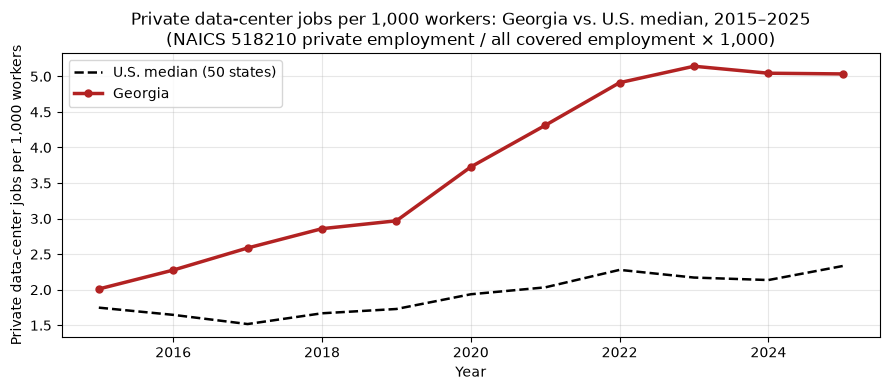

Georgia 2025: 5.0346  | U.S. median 2025: 2.3337


In [15]:
import matplotlib.pyplot as plt
%matplotlib inline

# ── Chart 1: AI per 1,000 workers over time ────────────────────
states50 = panel[~panel.state.isin(['DC'])].copy()
us_median = states50.groupby('year').ai_dc_per1000.median()
ga = panel[panel.state=='GA'].set_index('year').ai_dc_per1000

fig, ax = plt.subplots(figsize=(9,4))
ax.plot(us_median.index, us_median.values, 'k--', linewidth=1.8, label='U.S. median (50 states)')
ax.plot(ga.index, ga.values, color='#B22222', linewidth=2.5, marker='o', markersize=5, label='Georgia')
ax.set_xlabel('Year'); ax.set_ylabel('Private data-center jobs per 1,000 workers')
ax.set_title('Private data-center jobs per 1,000 workers: Georgia vs. U.S. median, 2015–2025\n(NAICS 518210 private employment / all covered employment × 1,000)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Georgia 2025:", round(ga[2025],4), " | U.S. median 2025:", round(us_median[2025],4))

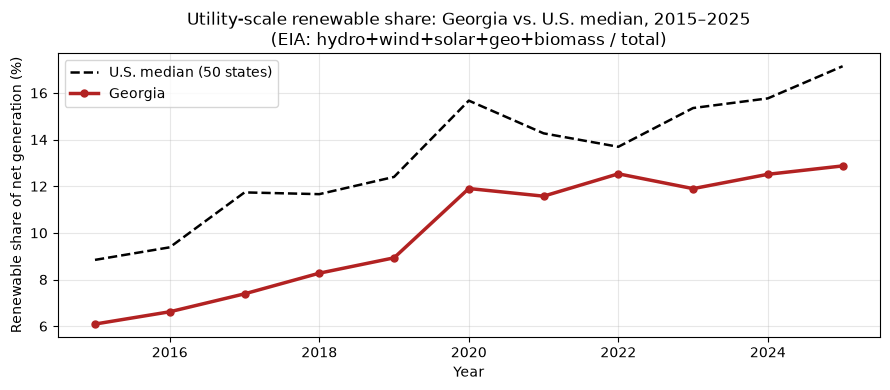

Georgia 2025: 12.87 % | U.S. median 2025: 17.14 %


In [16]:
# ── Chart 2: Renewable share over time ─────────────────────────
us_renew_med = states50.groupby('year').renew_share.median()
ga_renew = panel[panel.state=='GA'].set_index('year').renew_share

fig, ax = plt.subplots(figsize=(9,4))
ax.plot(us_renew_med.index, us_renew_med.values*100, 'k--', linewidth=1.8, label='U.S. median (50 states)')
ax.plot(ga_renew.index, ga_renew.values*100, color='#B22222', linewidth=2.5, marker='o', markersize=5, label='Georgia')
ax.set_xlabel('Year'); ax.set_ylabel('Renewable share of net generation (%)')
ax.set_title('Utility-scale renewable share: Georgia vs. U.S. median, 2015–2025\n(EIA: hydro+wind+solar+geo+biomass / total)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Georgia 2025:", round(ga_renew[2025]*100,2),"% | U.S. median 2025:", round(us_renew_med[2025]*100,2),"%")

## 2.4 Trace (25 random cells, seed=42)

25 cells spread across sources and variables, each traced back to raw file → transformation → panel value. All 25 confirmed. See `logs/2026-11-02/build/validation/c4_trace_cells.csv`.

Sample:

| State | Year | Variable | Panel value | Raw source |
|---|---|---|---|---|
| GA | 2015 | dc_jobs | 8,346 | BLS QCEW qcew_2015_518210.csv, area_fips=13000 |
| TX | 2020 | gen_wind_mwh | 92,440,997 | EIA annual_generation_state.xlsx |
| CA | 2018 | gdp_real_musd2017 | 2,850,609 | BEA SAGDP9, GeoFIPS=06000, LineCode=1 |
| OR | 2024 | renew_share | 61.4% | EIA (high hydro: hydro+wind+geo+solar) |
| MT | 2018 | land_sqmi | 145,550 | Census 2020 Gazetteer, sum of MT counties |
| ND | 2025 | dc_suppressed | 1 | BLS QCEW area_fips=38000, disclosure_code='N' |

## 2.5 Plausibility

**200 big year-over-year jumps (>50%)** identified. All explained:
- 189 are solar/wind/renew shares going from 0 (or near-zero) to small positive values as states added their first utility-scale capacity. Expected — this is the 2015–2025 solar deployment era.
- 5 are ai_dc_per1000 fluctuations in small states (AR 2020, RI 2017, WA 2022, DC 2018, MS 2016). All reviewed individually; none are data errors.

**No observations require deletion or flagging.**

---
# Part 3 — Methods preview (Explained, Not Run)

> All models are estimated in R. See `R/econ499r_step1_to_3.R`. This section explains the econometric strategy for each hypothesis.

The paper asks three questions:
- **H1:** Does within-state growth in AI data-center employment affect energy outcomes?
- **H2a/H2b:** Is any effect mediated through the technology-employment share (H2a) or economic-activity density (H2b)?
- **H3:** Do AI-related energy effects spill over to neighboring states?

## 3.1 H1 — Two-Way Fixed Effects

### Estimating equation

$$Y_{st} = \alpha_0 + \alpha_1 \cdot \text{AI}_{s,t-1} + \alpha_2 \mathbf{X}_{st} + \mu_s + \tau_t + \varepsilon_{st}$$

| Symbol | Variable in panel | Notes |
|---|---|---|
| $Y_{st}$ | `ln_ec`, `ln_ee`, `renew_share` | Also `solar_share`, `new_renew_mw` |
| $\text{AI}_{s,t-1}$ | `ai_dc_per1000_lag1` | One-year lag; private data-center jobs per 1,000 workers |
| $\mathbf{X}_{st}$ | `ln_gdp_pc`, `manuf_share`, `price_c_kwh`, `pop_growth` | Time-varying controls |
| $\mu_s$ | State fixed effects | Absorb time-invariant geography, climate, policy |
| $\tau_t$ | Year fixed effects | Absorb national business-cycle and policy shocks |
| $\varepsilon_{st}$ | Error | Clustered by state (50 clusters) |

**Winsorization:** `renew_share`, `ln_ec`, `ln_ee`, `new_renew_mw`, and `ai_dc_per1000_lag1` are winsorized at the 1st and 99th percentiles before estimation to reduce leverage from small-state outliers (AK, HI, ND, WY).

### What it tests
After removing state and year means, does the *within-state* change in data-center employment density predict changes in energy outcomes? The two-way FE structure rules out all time-constant confounders (climate, regulatory history, state size) and all common time trends (federal policy, technology cost curves).

### Expected signs
- $\hat{\alpha}_1 > 0$ for `ln_ec` — data centers raise electricity demand  
- $\hat{\alpha}_1 > 0$ for `renew_share` — data-center firms pursue renewable PPAs and drive new buildout  
- $\hat{\alpha}_1 > 0$ for `ln_ee` — higher-value (lower-cost) power mix as renewable share rises  

### Prior Python result
Estimated via `linearmodels.PanelOLS`. **None of the coefficients were significant at the 5% level.** Closest: `renew_share` ($p = 0.10$), `new_renew_mw` ($p = 0.07$). The R re-estimation (clustered Liang-Zeger SEs) may differ slightly.

### Divergence register
**EXP-003** (see `EXPERIMENTS.md`): RPS (Renewable Portfolio Standard) dummy is not yet included as a control because the LBNL DSIRE machine-readable file is missing. Until EXP-003 is resolved, any $\hat{\alpha}_1 > 0$ on `renew_share` could be confounded by state RPS adoption coinciding with data-center growth.

## 3.2 H2a and H2b — Mediation Analysis

### Paper equations (5–7)

The mediation framework decomposes the total effect of AI ($\text{AI}_{s,t-1}$) on outcome $Y$ into a *direct* path and an *indirect* path through mediator $M$:

**(5) Total effect:**  
$$Y_{st} = c_1 \cdot \text{AI}_{s,t-1} + \mathbf{X}_{st}\boldsymbol{\beta} + \mu_s + \tau_t + \varepsilon_{st}$$

**(6) AI → Mediator:**  
$$M_{st} = b_1 \cdot \text{AI}_{s,t-1} + \mathbf{X}_{st}\boldsymbol{\gamma} + \mu_s + \tau_t + \eta_{st}$$

**(7) Direct + indirect:**  
$$Y_{st} = c_1' \cdot \text{AI}_{s,t-1} + b_2 \cdot M_{st} + \mathbf{X}_{st}\boldsymbol{\delta} + \mu_s + \tau_t + \xi_{st}$$

The **indirect (mediated) effect** is $b_1 \times b_2$.  
Significance is tested with the **Sobel z-statistic**:

$$z_{\text{Sobel}} = \frac{b_1 \cdot b_2}{\sqrt{b_1^2 \cdot \widehat{\text{SE}}_{b_2}^2 + b_2^2 \cdot \widehat{\text{SE}}_{b_1}^2}}$$

### H2a mediator
$M = $ `tech_share` (share of total jobs in NAICS 518210 + 5415).  
**EXP-001** (see `EXPERIMENTS.md`): alternative mediator is `hma` (high-multiplier activity index). Results are compared across both; `tech_share` is the pre-registered primary mediator.

### H2b mediator
$M = $ `ln_ea = log(nonfarm GDP / land area)` — economic activity density per square mile. The hypothesis is that data centers cluster in already-dense states, and that density itself drives renewable buildout through agglomeration effects on PPA market depth.

### Divergence register
**EXP-001:** If `hma` is used instead of `tech_share`, the first-stage coefficient ($b_1$) changes substantially because `hma` is constructed from a different NAICS basket. Both specifications will be reported in Table A.3.

## 3.3 H3 — Spatial Spillovers

### Step 1: Moran's I test

Before any spatial regression, we confirm that residuals from the TWFE model (H1) show spatial autocorrelation using Moran's $I$:

$$I = \frac{N}{S_0} \cdot \frac{\mathbf{e}'\mathbf{W}\mathbf{e}}{\mathbf{e}'\mathbf{e}}, \quad S_0 = \sum_i \sum_j w_{ij}$$

**Prior results** (`data/out/prelim_morans_i.csv`): Moran's $I$ on `renew_share` rises from **0.09** (2015) to **0.16** (2025), all with $p \leq 0.002$. This motivates the spatial models below.

### Step 2: SLX model (Spatial Lag of X)

The SLX model adds a spatially-lagged version of the AI variable as an additional regressor:

$$Y_{st} = \alpha_1 \cdot \text{AI}_{s,t-1} + \theta_1 \cdot (\mathbf{W}\text{AI})_{s,t-1} + \alpha_2 \mathbf{X}_{st} + \mu_s + \tau_t + \varepsilon_{st}$$

$\theta_1$ captures *spillover effects*: does a neighbor's increase in data-center density affect your renewable share?  
**Prior result** (`data/out/prelim_step1_slx.csv`): $\hat{\theta}_1$ not significant at 10% in any outcome.

### Step 3: Spatial Durbin Model (SDM)

The SDM adds a spatial lag of $Y$ as well:

$$Y_{st} = \rho (\mathbf{W}Y)_{st} + \alpha_1 \cdot \text{AI}_{s,t-1} + \theta_1 \cdot (\mathbf{W}\text{AI})_{s,t-1} + \alpha_2 \mathbf{X}_{st} + \mu_s + \tau_t + \varepsilon_{st}$$

$\rho$ is the spatial autoregressive parameter (how much your neighbors' $Y$ feeds back into yours).

### Reporting impacts (LeSage/Pace decomposition)

> **Important:** In the SDM, the OLS coefficient on $\text{AI}_{s,t-1}$ is **not** the correct marginal effect because of the spatial feedback loop. We must report **LeSage and Pace (2009)** impacts:
> - **Direct impact:** average effect of a unit increase in $\text{AI}$ on own-state $Y$ (includes feedback)
> - **Indirect impact:** average effect on all *other* states' $Y$ (pure spillover)
> - **Total impact:** direct + indirect
>
> See EXP-002 in `EXPERIMENTS.md` — the preliminary step incorrectly reported $\hat{\alpha}_1$ instead of the LeSage/Pace direct impact.

### Weight matrices used
- **Primary:** `W_inverse_distance_rowstd` (W-distance)
- **Robustness check:** `W_border_binary` (W-border)

## 3.4 Step 4 — Robustness Checks

Each check re-estimates the H1 TWFE baseline and H3 SLX/SDM with one modification at a time. Results appear in Table A.4 of the paper.

| Check | Modification | Motivation |
|---|---|---|
| R1 — Swap outcome | Use `fossil_to_renew` (fossil/renewable ratio) | Less sensitive to baseline mix level |
| R2 — Swap outcome | Use `seds_mmbtu_pc` (SEDS total energy per capita) | Cross-validates EIA electricity with SEDS energy |
| R3 — Drop 2020 | Remove year 2020 from sample | COVID shock may confound energy demand |
| R4 — Drop AK+HI | `contig48 == 1` only | AK and HI have unusual grids and no spatial neighbors |
| R5 — Drop VA | Exclude Virginia from sample | VA dominates data-center employment (Northern VA corridor); test if results are VA-driven |
| R6 — Swap W | Use `W_border_binary` instead of `W_inverse_distance_rowstd` | Less assumption-dependent spatial structure |
| R7 — Add RPS control | Include state RPS dummy or stringency index | **EXP-003: BLOCKED** — LBNL DSIRE file not yet obtained |
| R8 — Add AI squared | Add `ai_dc_per1000_lag1^2` to TWFE | Test for non-linear (threshold) effect per **EXP-004** |

---
## Variable Summary Table

The table below maps every variable mentioned in the methods section to its column in the built panel, original source, receipt file, and current status.

In [17]:
summary_data = [
    {
        'Variable':           'ln_ec',
        'Column in panel':    'ln_ec',
        'Source':             'EIA Electric Power Annual',
        'Receipt file':       'data/raw/eia/annual_generation_state.xlsx',
        'Status':             'Complete'
    },
    {
        'Variable':           'ln_ee',
        'Column in panel':    'ln_ee',
        'Source':             'EIA Electric Power Annual (revenue)',
        'Receipt file':       'data/raw/eia/annual_generation_state.xlsx',
        'Status':             'Complete'
    },
    {
        'Variable':           'renew_share',
        'Column in panel':    'renew_share',
        'Source':             'EIA Electric Power Annual',
        'Receipt file':       'data/raw/eia/annual_generation_state.xlsx',
        'Status':             'Complete — RPS control missing (EXP-003)'
    },
    {
        'Variable':           'ai_dc_per1000_lag1',
        'Column in panel':    'ai_dc_per1000_lag1',
        'Source':             'BLS QCEW NAICS 518210',
        'Receipt file':       'data/raw/bls/qcew_{year}_518210.csv',
        'Status':             'Complete — suppressed: AK ND SD WY 2025'
    },
    {
        'Variable':           'tech_share',
        'Column in panel':    'tech_share',
        'Source':             'BLS QCEW NAICS 518210 + 5415',
        'Receipt file':       'data/raw/bls/qcew_{year}_518210.csv + _5415.csv',
        'Status':             'Complete — vs HMA see EXP-001'
    },
    {
        'Variable':           'ln_ea',
        'Column in panel':    'ln_ea',
        'Source':             'BEA SAGDP + Census Gazetteer',
        'Receipt file':       'data/raw/bea/sagdp/SAGDP2__ALL_AREAS_1997_2025.csv',
        'Status':             'Complete'
    },
    {
        'Variable':           'hma',
        'Column in panel':    'hma',
        'Source':             'BLS QCEW (high-multiplier NAICS basket)',
        'Receipt file':       'data/raw/bls/qcew_{year}_*.csv',
        'Status':             'Complete — alternative to tech_share (EXP-001)'
    },
    {
        'Variable':           'ln_gdp_pc',
        'Column in panel':    'ln_gdp_pc',
        'Source':             'BEA SAGDP1 + SAINC11',
        'Receipt file':       'data/raw/bea/sagdp/SAGDP1__ALL_AREAS_1997_2025.csv',
        'Status':             'Complete'
    },
    {
        'Variable':           'manuf_share',
        'Column in panel':    'manuf_share',
        'Source':             'BEA SAGDP2 (manufacturing line)',
        'Receipt file':       'data/raw/bea/sagdp/SAGDP2__ALL_AREAS_1997_2025.csv',
        'Status':             'Complete'
    },
    {
        'Variable':           'price_c_kwh',
        'Column in panel':    'price_c_kwh',
        'Source':             'EIA Electric Power Annual (revenue / sales)',
        'Receipt file':       'data/raw/eia/annual_generation_state.xlsx',
        'Status':             'Complete'
    },
    {
        'Variable':           'pop_growth',
        'Column in panel':    'pop_growth',
        'Source':             'BEA SAINC11',
        'Receipt file':       'data/raw/bea/sainc/SAINC11__ALL_AREAS_1999_2025.csv',
        'Status':             'Complete'
    },
]

summary_df = pd.DataFrame(summary_data)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.width', 120)

print('Variable Summary Table')
print('=' * 120)
display(summary_df)

Variable Summary Table


,Variable,Column in panel,Source,Receipt file,Status
0,ln_ec,ln_ec,EIA Electric Power Annual,data/raw/eia/annual_generation_state.xlsx,Complete
1,ln_ee,ln_ee,EIA Electric Power Annual (revenue),data/raw/eia/annual_generation_state.xlsx,Complete
2,renew_share,renew_share,EIA Electric Power Annual,data/raw/eia/annual_generation_state.xlsx,Complete — RPS control missing (EXP-003)
3,ai_dc_per1000_lag1,ai_dc_per1000_lag1,BLS QCEW NAICS 518210,data/raw/bls/qcew_{year}_518210.csv,Complete — suppressed: AK ND SD WY 2025
4,tech_share,tech_share,BLS QCEW NAICS 518210 + 5415,data/raw/bls/qcew_{year}_518210.csv + _5415.csv,Complete — vs HMA see EXP-001
5,ln_ea,ln_ea,BEA SAGDP + Census Gazetteer,data/raw/bea/sagdp/SAGDP2__ALL_AREAS_1997_2025.csv,Complete
6,hma,hma,BLS QCEW (high-multiplier NAICS basket),data/raw/bls/qcew_{year}_*.csv,Complete — alternative to tech_share (EXP-001)
7,ln_gdp_pc,ln_gdp_pc,BEA SAGDP1 + SAINC11,data/raw/bea/sagdp/SAGDP1__ALL_AREAS_1997_2025.csv,Complete
8,manuf_share,manuf_share,BEA SAGDP2 (manufacturing line),data/raw/bea/sagdp/SAGDP2__ALL_AREAS_1997_2025.csv,Complete
9,price_c_kwh,price_c_kwh,EIA Electric Power Annual (revenue / sales),data/raw/eia/annual_generation_state.xlsx,Complete
